# Линейная алгебра. Лабораторная работа 1, осень 2024



В этой лабораторной работе вы познакомитесь со средой Jupyter Notebook и библиотеками numpy и scipy.

## Часть 1. Библиотеки

В этой лабораторной работе вам понадобятся три библиотеки:

- `numpy` – основная библиотека для работы с матрицами;
- `scipy`, а точнее модуль `scipy.linalg`, содержащий множество функций линейной алгебры;
- `matplotlib` – графическая библиотека

Подключить их можно следующим образом:

In [1]:
# Запустите этот код
import numpy as np

import scipy.linalg as sla

import matplotlib.pyplot as plt
%matplotlib inline

Теперь вы можете позвать, скажем, функцию `scipy.linalg.det()` с помощью кода `sla.det()`, а функцию `numpy.exp()` – с помощью кода `np.exp()`.

**Основные объекты и операции линейной алгебры в NumPy и SciPy:**

Основной объект, с которым вам придётся работать и в этой, и в следующих лабораторных, – это, безусловно, матрицы. В библиотеке `numpy` они представлены классом `numpy.ndarray`. Матрицу можно создать из двумерного (а на самом деле и не только двумерного) массива следующим образом:

In [2]:
# Запустите этот код
A = np.array([[1, 2, 3], [4, 5, 6]])

print(A)
print(A.shape) # пара (число строк, число столбцов)

[[1 2 3]
 [4 5 6]]
(2, 3)


Обратите внимание, что матрица заполняется *по строкам*.

Есть и много других конструкторов матриц. Например, единичная матрица размера $n\times n$ создаётся с помощью функции `numpy.eye(n)`. Со всем многообразием конструкторов можно ознакомиться [на этой странице](https://docs.scipy.org/doc/numpy-1.10.1/reference/routines.array-creation.html).

Зачастую бывает нужно получить доступ к подматрицам данной матрицы, и numpy предоставляет множество удобных средств, как это сделать (вообще данная процедура называется slicing):
- элемент с номером `(i,j)`: `A[i,j]`
- i-я строка матрицы: `A[i,:]`
- j-й столбец матрицы: `A[:,j]`

**Внимание!** Оба варианта, и `A[i,:]`, и `A[:,j]` дают не строку или столбец, а одномерный вектор. Если вы хотите получить вектор-строку или вектор-столбец соответственно, используйте вот такой синтаксис: `A[i:i+1,:]` и `A[:,j:j+1]`
- строки с нулевой по i-ю: `A[:i+1,:]`
- столбцы с j-го по последний: `A[:,j:]`
- строки с i-й по k-ю: `A[i:k,:]`

В некоторых случаях нужно получить доступ к (прямоугольной) подматрице, элементы которой находятся на пересечении строк из списка `rows` и столбцов из списка `columns`. В этом случае `A[rows, columns]` даст не то, что вы ожидаете (можете попробовать это сделать сами и увидеть, что получится; только возьмите `rows` и `columns` одного размера). Справиться с этой задачей позволяет код `A[np.ix_(rows, columns)]`

*Умножение матриц* производится с помощью функции `np.dot()` либо оператора `@`. Есть три варианта написания: `A.dot(B)`, `np.dot(A, B)` и `A @ B`.

Обычные знаки арифметических действий (`+`, `-`, `*`) зарезервированы для поэлементных операций. Например, `A * B` – это матрица, элементами которой являются произведения $A_{ij}B_{ij}$. Помимо этих есть и множество других поэлементных операций. Например, `numpy.exp(A)` – это матрица, элементами которой являются экспоненты элементов матрицы `A`.

Чтобы получить матрицу, *транспонированную* к матрице `A`, напишите просто `A.T`.

В некоторых случаях бывает нужно создавать *случайные матрицы*: например, при проведении экспериментов или для инициализации итеративных методов. Средства для этого предоставляет пакет [numpy.random](https://docs.scipy.org/doc/numpy/reference/routines.random.html). Так, `np.random.rand(m,n)` – это матрица $m\times n$, элементы которой независимо выбраны из равномерного распределения на интервале `[0;1)`.

Для *решения систем линейных уравнений* в пакете `scipy.linalg` есть множество методов, рассмотрение которых выходит за пределы стандартного курса линейной алгебры. Мы вам пока предлагаем пользоваться функцией `scipy.linalg.solve`, основанной на методе Гаусса. Отметим, что `scipy.linalg.solve(A, B)` выдаёт решение уравнения $AX = B$ (или ошибку), где $B$ может быть как вектором, так и матрицей.

Найти обратную матрицу для матрицы $A$ можно с помощью функции `sla.inv(A)`.

**Копирование сложных объектов в Python**

Когда вы делаете присваивание каких-то сложных объектов, как правило, оно происходит по ссылке. Например, код
```
B = A
B[0,0] = 10
```
приведёт к изменению матрицы `A`.

Не попадайтесь в эту ловушку! Если вы хотите работать с копией как с независимой матрицей, используйте метод `copy()`:
```
B = A.copy()
```

**Где искать помощь**

Библиотеки `numpy` и `scipy` снабжены прекрасной документацией. Если у вас возникают вопросы о том, как работает та или иная функция (или даже как называется функция, выполняющая то, что вам нужно), вы почти всегда можете найти там ответы.

[Ссылка на документацию пакета scipy.linalg](https://docs.scipy.org/doc/scipy-0.18.1/reference/linalg.html)

Если у вас возникает какая-то ошибка и вы не можете понять, что вы делаете не так, то

1) в первую очередь попробуйте просто загуглить текст ошибки, наверняка в интернете кто-то уже сталкивался с такой ситуацией;  
2) поспрашивайте своих одногруппников, не было ли у них такой ошибки, и если была, то как они справлялись;  
3) попросите помощи у вашего учебного ассистента.




**И всё-таки задание**

**Задание 1.1 [0.2 балла за каждый пункт]** В качестве первого задания мы попросим вас отыскать соответствующие функции в библиотеке и сделать следующее:

- создайте нулевую матрицу $Z$ размера $3\times4$;

- создайте диагональную матрицу $5\times5$ с диагональными элементами 1, 2, 3, 4 и 5;

- найдите её след (не силою мысли, а с помощью библиотечных функций, конечно);

- найдите обратную к ней матрицу;

- сгенерируйте случайную матрицу $X$ размера $4\times5$;

- найдите определитель подматрицы матрицы $X$, расположенной на пересечении 2-й и 3-й строк и 1-го и 2-го столбцов; считаем, что строки и столбцы нумеруются с единицы (используйте slicing!). Такой определитель называется **минором** матрицы $X$;

- найдите произведение $X^TX$.

Пожалуйста, каждый пункт делайте в новом блоке и не забывайте распечатывать результаты.

In [ ]:
Z = np.zeros((3,4))

print(Z)

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


In [ ]:
a = np.diag([1,2,3,4,5])

print(a)

[[1 0 0 0 0]
 [0 2 0 0 0]
 [0 0 3 0 0]
 [0 0 0 4 0]
 [0 0 0 0 5]]


In [ ]:
tr = np.trace(a)
print(tr)

15


In [ ]:
b = np.linalg.inv(a)
print(b)

[[1.         0.         0.         0.         0.        ]
 [0.         0.5        0.         0.         0.        ]
 [0.         0.         0.33333333 0.         0.        ]
 [0.         0.         0.         0.25       0.        ]
 [0.         0.         0.         0.         0.2       ]]


In [ ]:
X = np.random.rand(4,5)
print(X)

[[0.53582334 0.06799757 0.02640432 0.58638071 0.43659424]
 [0.89919476 0.55858968 0.58160979 0.91897236 0.09478182]
 [0.4583456  0.40250176 0.78110112 0.42001848 0.48383196]
 [0.47142692 0.7916317  0.67263527 0.42680315 0.07154496]]


In [ ]:
submatrix = X[1:3, 0:2]
detr = np.linalg.det(submatrix)
print(detr)

0.1059003559683127


In [ ]:
X_T = X.T
print(X_T.dot(X))

[[1.5279819  1.09639701 1.21224116 1.53425172 0.57465517]
 [1.09639701 1.10533452 1.17355064 1.06013002 0.33401197]
 [1.21224116 1.17355064 1.4015243  1.16512606 0.49269935]
 [1.53425172 1.06013002 1.16512606 1.54692898 0.57686629]
 [0.57465517 0.33401197 0.49269935 0.57686629 0.43881017]]


## Часть 2. Время

Питон мотивирует пользоваться библиотечными функциями, когда они доступны, а не писать собственные. Библиотечные функции основаны на современных алгоритмах, обычно пишутся на более эффективных языках, таких как C++ или Fortran, а кроме того, оптимизированы для работы на многопроцессорных устройствах, так что обогнать эти решения просто так вы не сможете.

**Задание 2.1 [1 балл]**
Мы предлагаем вам убедиться в этом самим. Напишите функцию `my_det`, которая вычисляла бы определитель матрицы с помощью элементарных преобразований над строками. Функция должна выкидывать `ValueError` в случаях, если матрица не является квадратной.

In [ ]:
def my_det(X):
    '''
    Parameters
    ----------
    X : array_like

    Returns
    -------
    det : float
        Determinant of `a`.
    '''
    X = X.astype(np.float128)
    rows, cols = X.shape
    if rows != cols:
        raise ValueError

    det = 1
    sign = 1

    for i in range(rows):
        max_row_index = np.argmax(abs(X[i:, i])) + i
        if max_row_index != i:
            X[[i, max_row_index]] = X[[max_row_index, i]]
            sign *= -1

        pivot = X[i, i]
        if pivot == 0:
            return 0

        for j in range(i + 1, rows):
            factor = X[j, i] / pivot
            X[j] = X[j] - factor * X[i]

    for i in range(rows):
        det *= X[i, i]

    det *= sign

    return det

Простая проверка:

In [ ]:
# Запустите этот блок кода
X = np.array([[0,0,1], [0,1,0], [1,0,0]])
print(my_det(X))

-1.0


На случай, если нам просто повезло с этой матрицей, имеет смысл написать чуть более хитрые тесты. Мы сгенерируем несколько случайных матриц $50\times50$ с помощью функции `numpy.random.rand` и сравним ответ, выдаваемый нашей функцией, с настоящим определителем (результатом работы библиотечной функции `scipy.linalg.det`):

In [ ]:
# Запустите этот блок кода
for _ in range(50):
    X = np.random.rand(50, 50)
    if np.abs(my_det(X) - sla.det(X)) > 1e-6:
        print('FAILED')

Если вы ни разу не получили `FAILED`, то ваша функция работает правильно.

Теперь давайте сравним скорость работы вашей функции и библиотечной функции `scipy.linalg.det`. В Питоне есть несколько способов измерения времени; мы воспользуемся декоратором `%timeit`. Будучи написан перед функцией, он запускает её некоторое количество раз, выбирает три случайных запуска и возвращает длительность самого быстрого из них. Модификатор `-o` между декоратором и функцией позволяет сохранять результаты работы декоратора в переменную.

Приготовьтесь, что следующий блок может работать сравнительно долго.

15.7 µs ± 2.12 µs per loop (mean ± std. dev. of 7 runs, 100000 loops each)
224 µs ± 7.19 µs per loop (mean ± std. dev. of 7 runs, 1000 loops each)
136 µs ± 32 µs per loop (mean ± std. dev. of 7 runs, 10000 loops each)
20.4 ms ± 1.42 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
64.2 ms ± 33.1 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
5.43 s ± 518 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


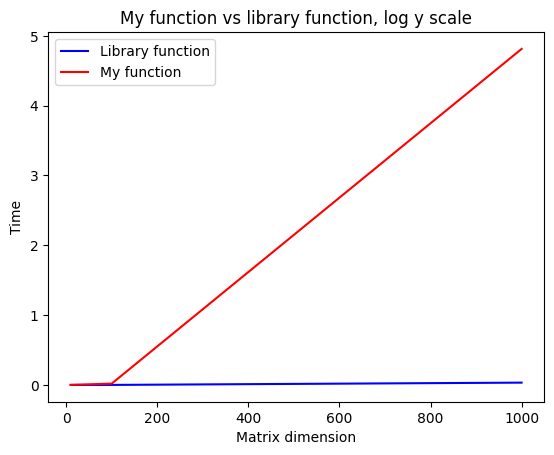

In [ ]:
# Запустите этот блок кода
lib_times = []
my_times = []
dimensions = [10, 100, 1000]
for dim in dimensions:
    A = np.random.rand(dim, dim)
    res_lib = %timeit -o sla.det(A)
    lib_times.append(res_lib.best)
    res_my = %timeit -o my_det(A)
    my_times.append(res_my.best)

plt.plot(dimensions, lib_times, color='blue', label='Library function')
plt.plot(dimensions, my_times, color='red', label='My function')
plt.title('My function vs library function, log y scale')
plt.ylabel('Time')
plt.xlabel('Matrix dimension')
plt.legend()

У вас должны были получиться графики, показывающие, как растёт с ростом размерности матрицы время вычисления определителя. Поскольку они вышли не больно-то красивыми, мы нарисуем их в *логарифмическом масштабе* по оси у:

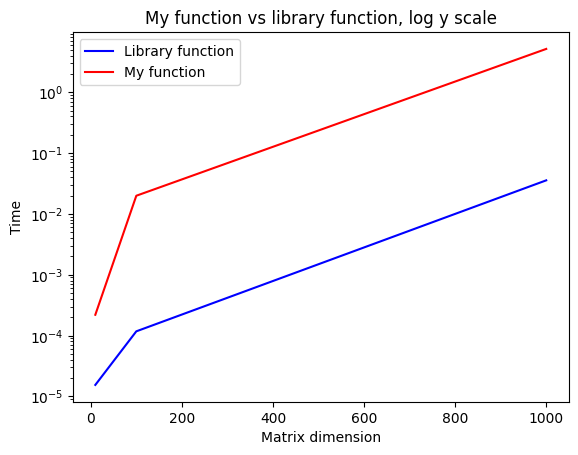

In [ ]:
# Запустите этот блок кода
plt.semilogy(dimensions, lib_times, color='blue', label='Library function')
plt.semilogy(dimensions, my_times, color='red', label='My function')
plt.title('My function vs library function, log y scale')
plt.ylabel('Time')
plt.xlabel('Matrix dimension')
plt.legend()

Вы можете убедиться, что библиотечная функция работает *гораздо* быстрее.

## Часть 3. Точность

Наверняка вы уже что-то знаете про floating point arithmetics и связанные с этим трудности и понимаете, что на компьютере вычисления с вещественными числами производятся лишь с ограниченной точностью.

**Задание 3.1 [0.6 балла]** В качестве первого примера, показывающего различие между длинной арифметикой целых чисел и floating point arithmetics, предлагаем вам перемножить две пары матриц:

$$
\begin{pmatrix}
1 & 0\\
10^{20} & 1
\end{pmatrix}
\cdot
\begin{pmatrix}
10^{-20} & 1\\
0 & 1 - 10^{20}
\end{pmatrix}
$$
и
$$
\begin{pmatrix}
1. & 0.\\
10.^{20} & 1.
\end{pmatrix}
\cdot
\begin{pmatrix}
10.^{-20} & 1.\\
0. & 1. - 10.^{20}
\end{pmatrix}
$$
Во втором случае мы специально указали Питону (поставив везде десятичные точки), что хотим работать не с целыми числами, а с числами с плавающей точкой. Посмотрим, получатся ли одинаковые ответы:

In [ ]:
K = np.array([[1,0],[10**20, 1]],dtype = object)
L = np.array([[10**(-20), 1], [0, 1-10**20]], dtype = object)
M = np.array([[1.,0.],[10**20., 1.]], dtype = object)
N = np.array([[10.**(-20), 1.], [0., 1.-10.**20]], dtype = object)
print(K.dot(L))
print(M.dot(N))

[[1e-20 1]
 [1.0 1]]
[[1e-20 1.0]
 [1.0 0.0]]


И какой из них правильный?

---
В 1 случае результат правильный. Во 2 случае для чисел с плавающей точкой появляется ошибка вычислений из-за ограниченной точности.

**Задание 3.2 [0.75 балла]** Впрочем, и с целыми числами тоже не всегда всё хорошо. Напишите функцию, генерирующую *матрицу Паскаля* заданной размерности $n$, то есть матрицу $P$, в которой $P_{ij} = C_{i+j}^i$. В этом задании нельзя пользоваться библиотечной функцией `scipy.linalg.pascal` или её аналогами из других библиотек. Обратите внимание, что использование факториалов крайне нежелательно, так как быстро приведёт к переполнению.

В этом задании вы можете использовать цикл ``for``.

In [11]:
def my_pascal(dim):
    """
    Мы создали для вас матрицу из нулей размера dim x dim,
    но вы можете ей не пользоваться, если не хотите
    """
    P = np.zeros((dim, dim))
    for i in range(dim):
        for j in range(dim):
            if j == 0:
                P[i, j] = 1
            else:
                P[i, j] = P[i, j - 1] * (i + j) // j

    return P
dim = np.random.randint(2,8)
print(my_pascal(dim))

[[  1.   1.   1.   1.   1.   1.   1.]
 [  1.   2.   3.   4.   5.   6.   7.]
 [  1.   3.   6.  10.  15.  21.  28.]
 [  1.   4.  10.  20.  35.  56.  84.]
 [  1.   5.  15.  35.  70. 126. 210.]
 [  1.   6.  21.  56. 126. 252. 462.]
 [  1.   7.  28.  84. 210. 462. 924.]]


Определитель матриц Паскаля всегда будет равен 1 \\
Это можно доказать, если получится свести матрицу Паскаля к верхнетреугольному виду. Для этого докажем, что:
Вычитание из $i$-й строки $i - 1$-й строки даст смещение $i$-й строки вправо на 1 (Например: 2 строка матрицы Паскаля $5 \times 5$, она выглядит так: 1 2 3 4 5. После вычитания 1 строки преобразится в 0 1 2 3 4).

Док-во:

Рассмотрим матрицу Паскаля произвольного размера n. Рассмотрим $i$-ю строку данной матрицы. Она состоит из элементов:
 \begin{pmatrix}\binom{i-1}{0} & \binom{i}{1} & \binom{i + 1}{2} & \binom{i + 2}{3} & ... & \binom{i + n - 2}{n - 1}\end{pmatrix}

Рассмотрим $i - 1$-ю строку:

\begin{pmatrix}\binom{i - 2}{0} & \binom{i - 1}{1} & \binom{i}{2} & \binom{i + 1}{3} & ... & \binom{i + n - 3}{n - 1}\end{pmatrix}

После вычитания $i$-я строка:

 \begin{pmatrix}\binom{i - 1}{0} - \binom{i - 2}{0} & \binom{i}{1} - \binom{i - 1}{1} & \binom{i + 1}{2} - \binom{i}{2} & \binom{i + 2}{3} - \binom{i + 1}{3} & ... & \binom{i + n - 2}{n - 1} - \binom{i + n - 3}{n - 1}\end{pmatrix}

 По свойству биномиальных коэффициентов:

$\binom{n}{k} = \binom{n-1}{k} + \binom{n-1}{k-1} \Rightarrow \binom{n-1}{k-1} = \binom{n}{k} - \binom{n-1}{k}$

Тогда, используя это свойство: $i$-я строка:

 \begin{pmatrix}0 & \binom{i - 1}{0} & \binom{i}{1} & \binom{i + 1}{2} & ... & \binom{i + n - 3}{n - 2}\end{pmatrix}

И о чудо, все элементы в $i$-й строке действительно сместились вправо на одну позицию.
$Q.E.D$

Теперь надо придумать, как используя то, что мы доказали, привести матрицу Паскаля к верхнетреугольному виду.
1. Начиная с нижней строки будем вычитать строку, стоящую над ней. В первый раз будем это проделывать до 1-й строки. Благодаря этим преобразованиям, у нас получилось занулить все элементы в 1 столбце, кроме диаганального($a_{11}$). Также получилось сместить все строчки кроме 1-й на одну позицию вправо, значит, мы смогли сместить всю матрицу Паскаля на один вправо, при этом сохранилась структура матрицы: каждый элемент  получается путем сложения элемента сверху и элемента слева(1 столбец не учитываем).
2. Полученная матрица будет содержать снизу справа блок размеров $n - 1 \times n - 1$, сохраняющий свойства матрицы Паскаля(1 стобец и 1 строку "отбрасываем",т.к. их мы "причесали"). Опять вспомним свойство биномиальных коэффициентов: $\binom{n}{k} = \binom{n-1}{k} + \binom{n-1}{k-1}$
При вычитании элемента сверху - $\binom{i - 1}{j}$,нас останется только $\binom{i - 1}{j - 1}$, что равно элементу стоящему слева - $\binom{i - 1}{j - 1}$
Значит мы и дальше сможем смещать строки на 1 вправо, т.к. структура сохранилась
3. Будем проделывать действия пункта 1, но теперь влоть до 2-строки, потом вплоть до 3-й строки и т.д. На каждом таком шаге на диагональную позицию $a_{ii}$  будет вставать единица, где $i$ - номер строки, вплоть до которой мы идем.
4. В итоге мы приведем матрицу к верхнетреугольному виду, так что на диагонали будут стоять только единицы. Заметим, что мы только вычитали строки матрицы из строк матрицы. Это элементарное преобразование не меняет определитель.
5. Значит, определитель преобразованной верхнетреугольной матрицы равен определителю матрицы Паскаля. Определитель верхнетреугольной матрицы - произведение всех ее диагональных элементов, что равно $1^n = 1$
6. Тогда определитель матрицы Паскаля тоже равен 1 - $Q.E.D$

А теперь вычислите определитель матрицы Паскаля $30\times30$ с помощью библиотечной функции `scipy.linalg.det`:

In [12]:
print(sla.det(my_pascal(dim=30)))

-1.643438812844882e+51


Разница заметна невооружённым взглядом!

## Часть 4. Матричные вычисления

Вы уже видели, что использования циклов (и самописных вычислений в целом) в Питоне лучше по возможности избегать, и важно уметь находить способы делать всё библиотечными средствами.

В качестве примера рассмотрим две задачи:

**1.** Предположим, нужно вычислить суммы элементов в каждой строке матрицы `A`. Ясно, что можно написать простую функцию с двумя циклами, которая это посчитает, но так лучше не делать. Правильный способ такой:
```
A.sum(axis=1)
```
Параметр `axis=1` означает, что суммы берутся по строкам. Если вы хотите просуммировать по столбцам, укажите `axis=0`. Если вообще пропустить параметр `axis` (вызвать `A.sum()`), то функция вернёт сумму *всех* элементов матрицы.

**2.** Теперь допустим, что нам нужно каждый столбец матрицы `A` умножить на некоторое число. Более точно, пусть у нас есть (одномерный) вектор `w = np.array([w_1,...,w_n])`, и мы должны `i`-й столбец `A` умножить на число `w_i`. Опять же, это можно сделать в пару циклов, но лучше использовать операцию поэлементного умножения:
```
A * w.reshape((1,n))
```
Оператор `reshape` нужен для того, чтобы из одномерного вектора сделать вектор-строку.

Аналогично, если на числа `w_1,...,w_n` умножаются *строки* матрицы, нужно превратить `w` в вектор-столбец:
```
A * w.reshape((n,1))
```

Дальше вам будет предложено попрактиковаться в матричных вычислениях. В следующих трёх заданиях нельзя пользоваться циклами, а также конструкциями `map` и `reduce` и им подобными; вместо этого постарайтесь свести всё к матричным операциям из `numpy` (но, опять же, не `np.vectorize` или чему-то подобному). Чтобы убедиться, что получилось именно то, что нужно, пишите собственные тесты со случайными матрицами.

**Задание 4.1 [0.75 балла]** Напишите функцию `prod_and_sq_sum(A)`, вычисляющую произведение диагональных элементов, а также сумму квадратов диагональных элементов квадратной матрицы `A`.

In [ ]:
def prod_and_sq_sum(A):
    if A.shape[0] != A.shape[1]:
      raise ValueError("На вход подана не диагональная матрица")
    diagonal_elements = np.diag(A)
    prod = np.prod(diagonal_elements)
    sq_sum = np.sum(diagonal_elements ** 2)

    return prod, sq_sum
n = np.random.randint(3,11)
A = np.random.randint(1, 10, size=(n, n))
prod, sq_sum = prod_and_sq_sum(A)
print(f"Матрица размера {n} x {n}: ")
print(A)
print("Произведение диагональных элементов: ", prod)
print("Сумма квадратов диагональных элементов: ", sq_sum)

Матрица размера 4 x 4: 
[[4 5 1 8]
 [5 9 9 3]
 [7 4 2 9]
 [7 7 9 6]]
Произведение диагональных элементов:  432
Сумма квадратов диагональных элементов:  137


**Задание 4.2 [0.75 балла]** Для матриц `A` и `B` размера $m\times n$ обозначим через $a_1,\ldots,a_n$ и $b_1,\ldots,b_n$ соответственно их столбцы; пусть также $\lambda_1, \ldots, \lambda_n$ – некоторые числа. Напишите функцию `f(A, B, lmbd, k)`, вычисляющую

$$\sum_{i=1}^{\min(k,n)}\lambda_ia_ib_i^T$$

In [ ]:
def f(A, B, lmbd, k):
    m, n = A.shape
    lmbd = lmbd[:min(n, k)]
    A = A[:, :min(n, k)]
    B = B[:, :min(n, k)]
    A_scaled = A * lmbd

    result = A_scaled @ B.T

    return result

m, n = np.random.randint(2, 6), np.random.randint(2, 6)
A = np.random.randint(1, 10, size=(m, n))
B = np.random.randint(1, 10, size=(m, n))
lmbd = np.random.randint(1, 10, size=n)
k = np.random.randint(1, n + 1)
print("Тест для матриц: ")
print("A: ", A)
print("B: ", B)
print("Набор чисел lambda: ", lmbd)
print("При k = ", k)
print("Результат: ")
print(f(A, B, lmbd, k))

Тест для матриц: 
A:  [[8 2 9 9 4]
 [7 1 8 3 4]
 [3 5 6 9 2]]
B:  [[1 5 9 8 3]
 [3 6 6 6 8]
 [4 4 5 5 1]]
Набор чисел lambda:  [4 4 2 3 4]
При k =  3
Результат: 
[[234 252 250]
 [192 204 208]
 [220 228 188]]


**Задание 4.3 [0.75 балла]** Напишите функцию `get_diag(A,B)`, принимающую две квадратных матрицы матрицы `A` и `B` одного размера и возвращающую вектор диагональных элементов произведения `AB`, не вычисляя произведение целиком.

In [ ]:
def get_diag(A, B):
    if A.shape != B.shape or A.shape[0] != A.shape[1]:
        raise ValueError("Матрицы должны быть квадратными и одинакового размера.")
    n = A.shape[0]
    diag_elements = np.sum(A * B.T, axis=1)

    return diag_elements
n = np.random.randint(2,8)
A = np.random.randint(1,10, size = (n,n))
B = np.random.randint(1,10, size = (n,n))
print("Тест для матриц:")
print("A: ", A)
print("B: ", B)
print("Вектор диагональных элементов AB: ")
print(get_diag(A, B))

Тест для матриц:
A:  [[4 3 5]
 [2 1 4]
 [1 4 7]]
B:  [[6 4 3]
 [7 5 2]
 [5 7 9]]
Вектор диагональных элементов AB: 
[70 41 74]


## Часть 5. Комплексные числа и геометрия

У вас уже была возможность убедиться, что многие операции над комплексными числами имеют наглядную геометрическую интерпретацию. В этом задании вам будет предложено этим воспользоваться.

В Python число $i$ (мнимая единица) обозначено через `1j`. Так, число $0,5 + 1,2i$ будет иметь вид `0.5 + 1.2 * 1j`.

При выполнении задания вы должны работать с точками плоскости как с комплексными числами. Любые преобразования должны быть реализованы с помощью операций над комплексными числами: сложения, вычитания, умножения, деления, возведения в степень и комплексного сопряжения.

**Задание 5.1 [0.5 баллов]** Напишите функцию `shrink_rotate`, которая принимает на вход:
- заданную в виде комплексного числа точку $X$, которую мы подвергаем преобразованию,
- заданную в виде комплексного числа точку $A$,
- действительный коэффициент `coef`,
- угол `alpha`, заданный в радианах

и осуществляет следующее преобразование: мы берём вектор $AX$, умножаем его на `coef`, поворачиваем вокруг точки $A$ на угол `alpha` против часовой стрелки, после чего возвращаем конец полученного вектора. Ниже (левая картинка) мы приводим иллюстрацию действия этого преобразования:

<img src="ShrinkRotate.png">

**Задание 5.2 [0.5 баллов]** Напишите функцию `shrink_rotate_conj`, которая сначала делает то же самое, что и `shrink_rotate`, а после этого отражает вектор $AY$ относительно горизонтальной прямой, проходящей через точку $A$, и возвращает точку $Y'$ (см. правую часть рисунка).

**Задание 5.3 [0.5 баллов]** Напишите функцию `geometric_inverse`, которая принимает на вход:
- заданную в виде комплексного числа точку $X$, которую мы подвергаем преобразованию,
- заданную в виде комплексного числа точку $A$,
- положительное действительное число $r$

и осуществляет инверсию точки $X$ относительно окружности с центром $A$ радиуса $r$. [Определение инверсии вы можете посмотреть здесь](https://ru.wikipedia.org/wiki/%D0%98%D0%BD%D0%B2%D0%B5%D1%80%D1%81%D0%B8%D1%8F_(%D0%B3%D0%B5%D0%BE%D0%BC%D0%B5%D1%82%D1%80%D0%B8%D1%8F)).

In [41]:
def shrink_rotate(x, a, coef=1., angle=0.):
    vector = x - a
    transformed_vector = vector * coef * np.exp(1j * angle)
    return a + transformed_vector

def shrink_rotate_conj(x, a, coef=1., angle=0.):
    y = shrink_rotate(x, a, coef, angle)
    reflected_y = a + (y - a).conjugate()
    return reflected_y

def geometric_inverse(x, a, r):
    diff = x - a
    distance_squared = abs(diff)**2
    x_inv = a + (r**2 / distance_squared) * diff
    return x_inv

**Задание 5.4 [0.75 баллов]** Рассмотрим следующий процесс:

```
z = 0.5 + 0.*1j
max_iter = 100000
funcs = [
    (lambda t: shrink_rotate(t, 0. + 1.*1j, coef=0.5, angle=0.)),
    (lambda t: shrink_rotate(t, 1. + 0.*1j, coef=0.5, angle=0.)),
    (lambda t: shrink_rotate(t, -1. + 0.*1j, coef=0.5, angle=0.))
]

for n_iter in range(max_iter):
    n_func = np.random.choice(len(funcs))
    z = funcs[n_func](z)
```

Запустите его и нарисуйте множество точек, получающихся на итерациях начиняя с десятой.

*Указание*. Представьте квадрат $[-1,1]\times[-1,1]$ матрицей пикселей 1000x1000. Сначала все элементы матрицы положим нулями, а на каждой итерации начиная с десятой будем присваивать единицу соответствующему пикселю этой матрицы. То, что получилось, можно нарисовать с помощью функции `plt.imshow(..., cmap='gray')`. Картинку лучше сделать побольше, предварив `imshow` вызовом `plt.figure(figsize=(20, 20))`.

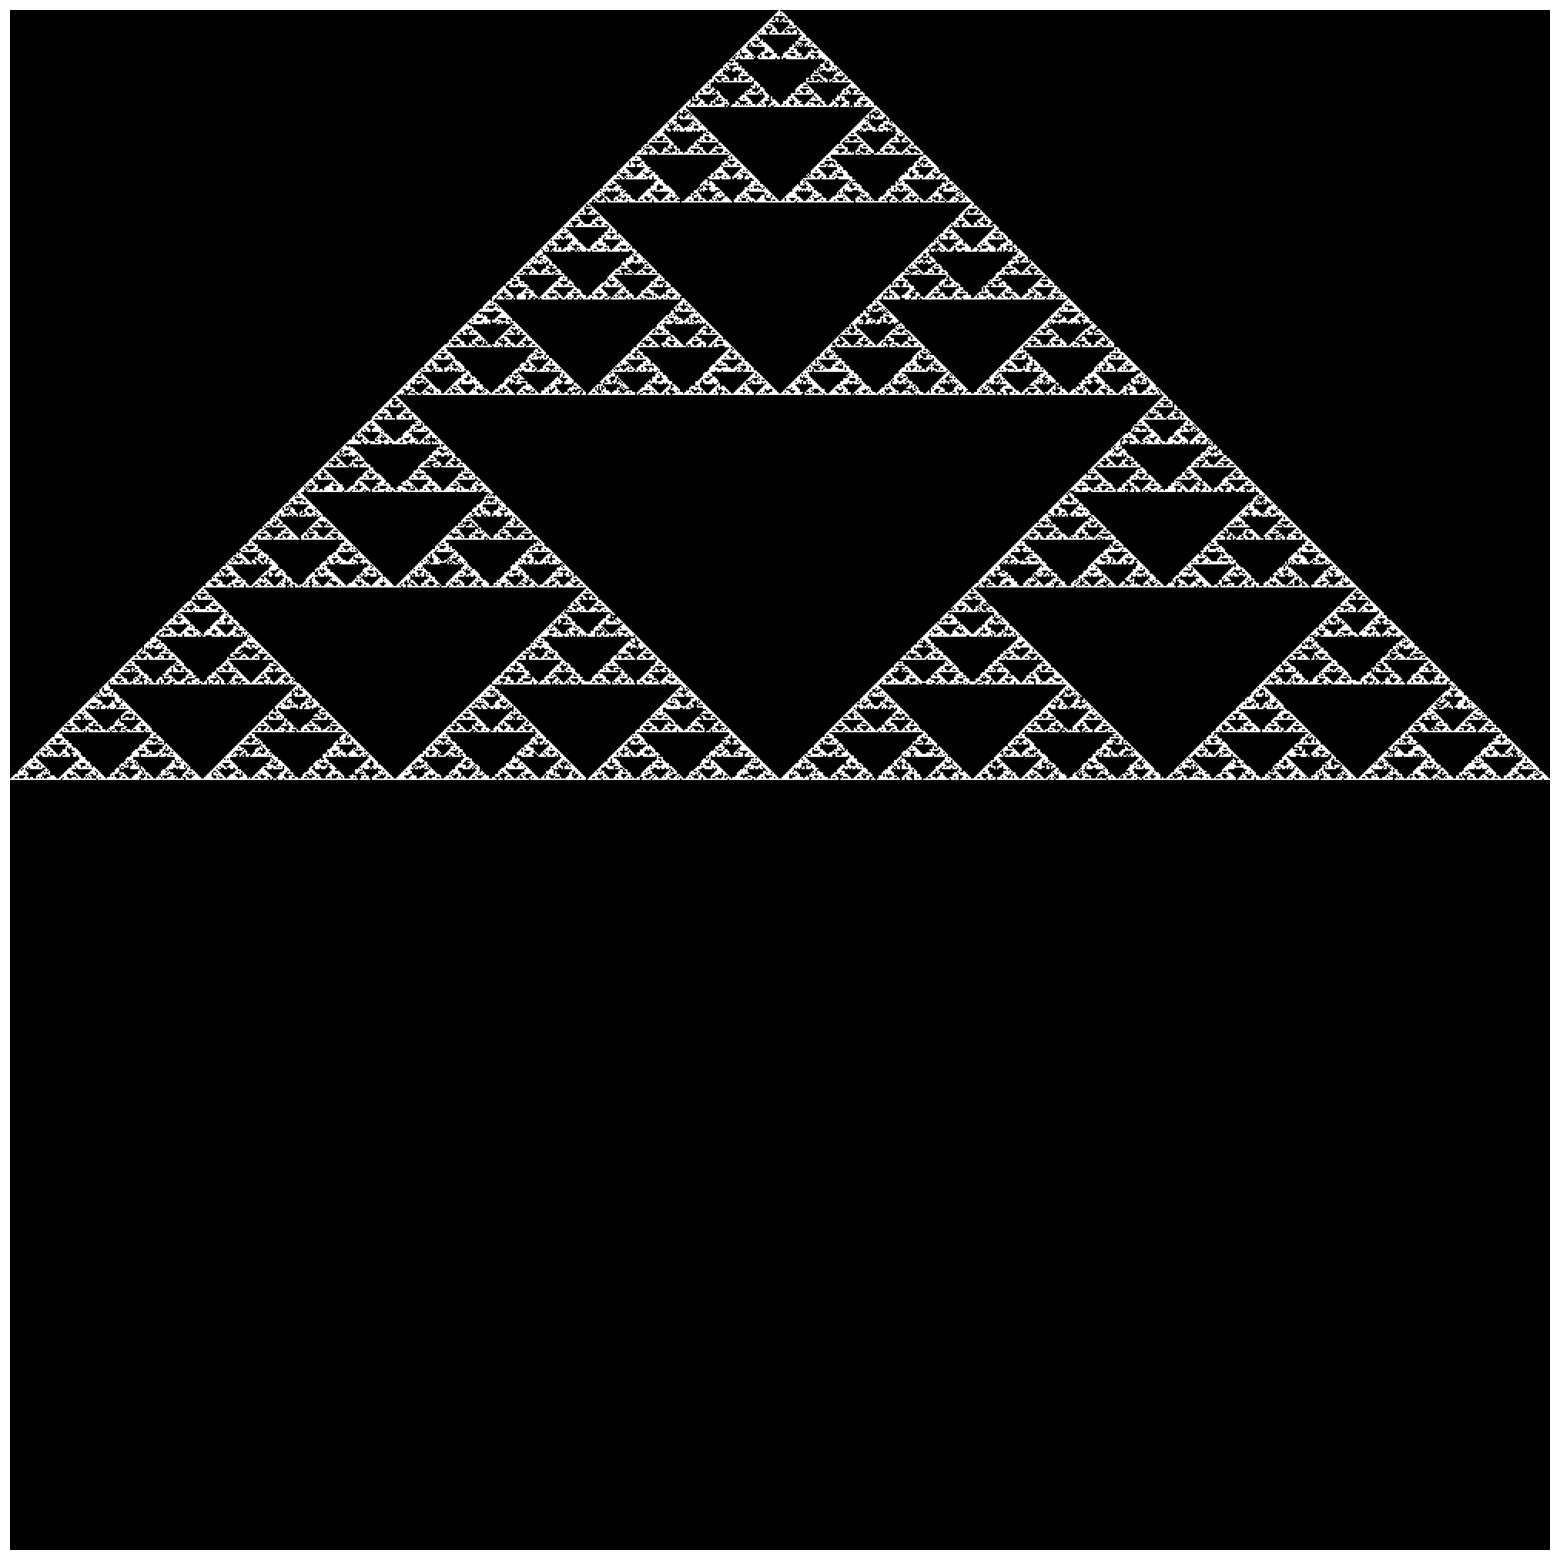

In [15]:
z = 0.5 + 0j
max_iter = 100000
grid_size = 1000
region = [-1, 1, -1, 1]

funcs = [
    lambda t: shrink_rotate(t, 0 + 1j, coef=0.5, angle=0),
    lambda t: shrink_rotate(t, 1 + 0j, coef=0.5, angle=0),
    lambda t: shrink_rotate(t, -1 + 0j, coef=0.5, angle=0)
]

pixels = np.zeros((grid_size, grid_size), dtype=int)

def scale_to_grid(z, region, grid_size):
    xmin, xmax, ymin, ymax = region
    real_scaled = int((z.real - xmin) / (xmax - xmin) * grid_size)
    imag_scaled = int((z.imag - ymin) / (ymax - ymin) * grid_size)
    return real_scaled, imag_scaled

for n_iter in range(max_iter):
    n_func = np.random.choice(len(funcs))
    z = funcs[n_func](z)

    if n_iter >= 10:
        x, y = scale_to_grid(z, region, grid_size)
        if 0 <= x < grid_size and 0 <= y < grid_size:
            pixels[grid_size - y - 1, x] = 1

plt.figure(figsize=(20, 20))
plt.imshow(pixels, cmap='gray')
plt.axis('off')
plt.show()


**Задание 5.5 [0.75 баллов]** Попробуйте объяснить, почему получается именно эта фигура.

Причины такой фигуры: \\
1. Каждая итерация функции сжимает точку относительно выбранного центра (выбор между $0+1j, 1 + 0j, -1+0j$)  с коэффициентом 0.5(coef = 0.5). Это приводит к тому, что точки концентрируются всё ближе к центрам, формируя вложенные копии начальной структуры. При этом промежуточные зоны остаются незаполненными. \\
2. Поскольку угол поворота равен 0, результирующее множество зависит только от последовательного сжатия векторов к трём точкам. Если бы был задан поворот, структура множества изменилась бы, добавив закрученность.
3. На каждом шаге выбирается одна из трёх функций с равной вероятностью. Это приводит к "разветвлённой" структуре множества, где каждая ветвь связана с движением к одной из трёх фиксированных точек.
4. Так как происходит сжатие именно к трем точкам ($0+1j, 1 + 0j, -1+0j$),которые, в свою очередь, образуют вершины равностороннего треугольника, то фрактал будет приближаться к треугольной структуре.

**Задание 5.6 [0.5 баллов]** Поэкспериментируйте с другими преобразованиями. Попробуйте найти какой-нибудь другой красиво выглядящий фрактал.

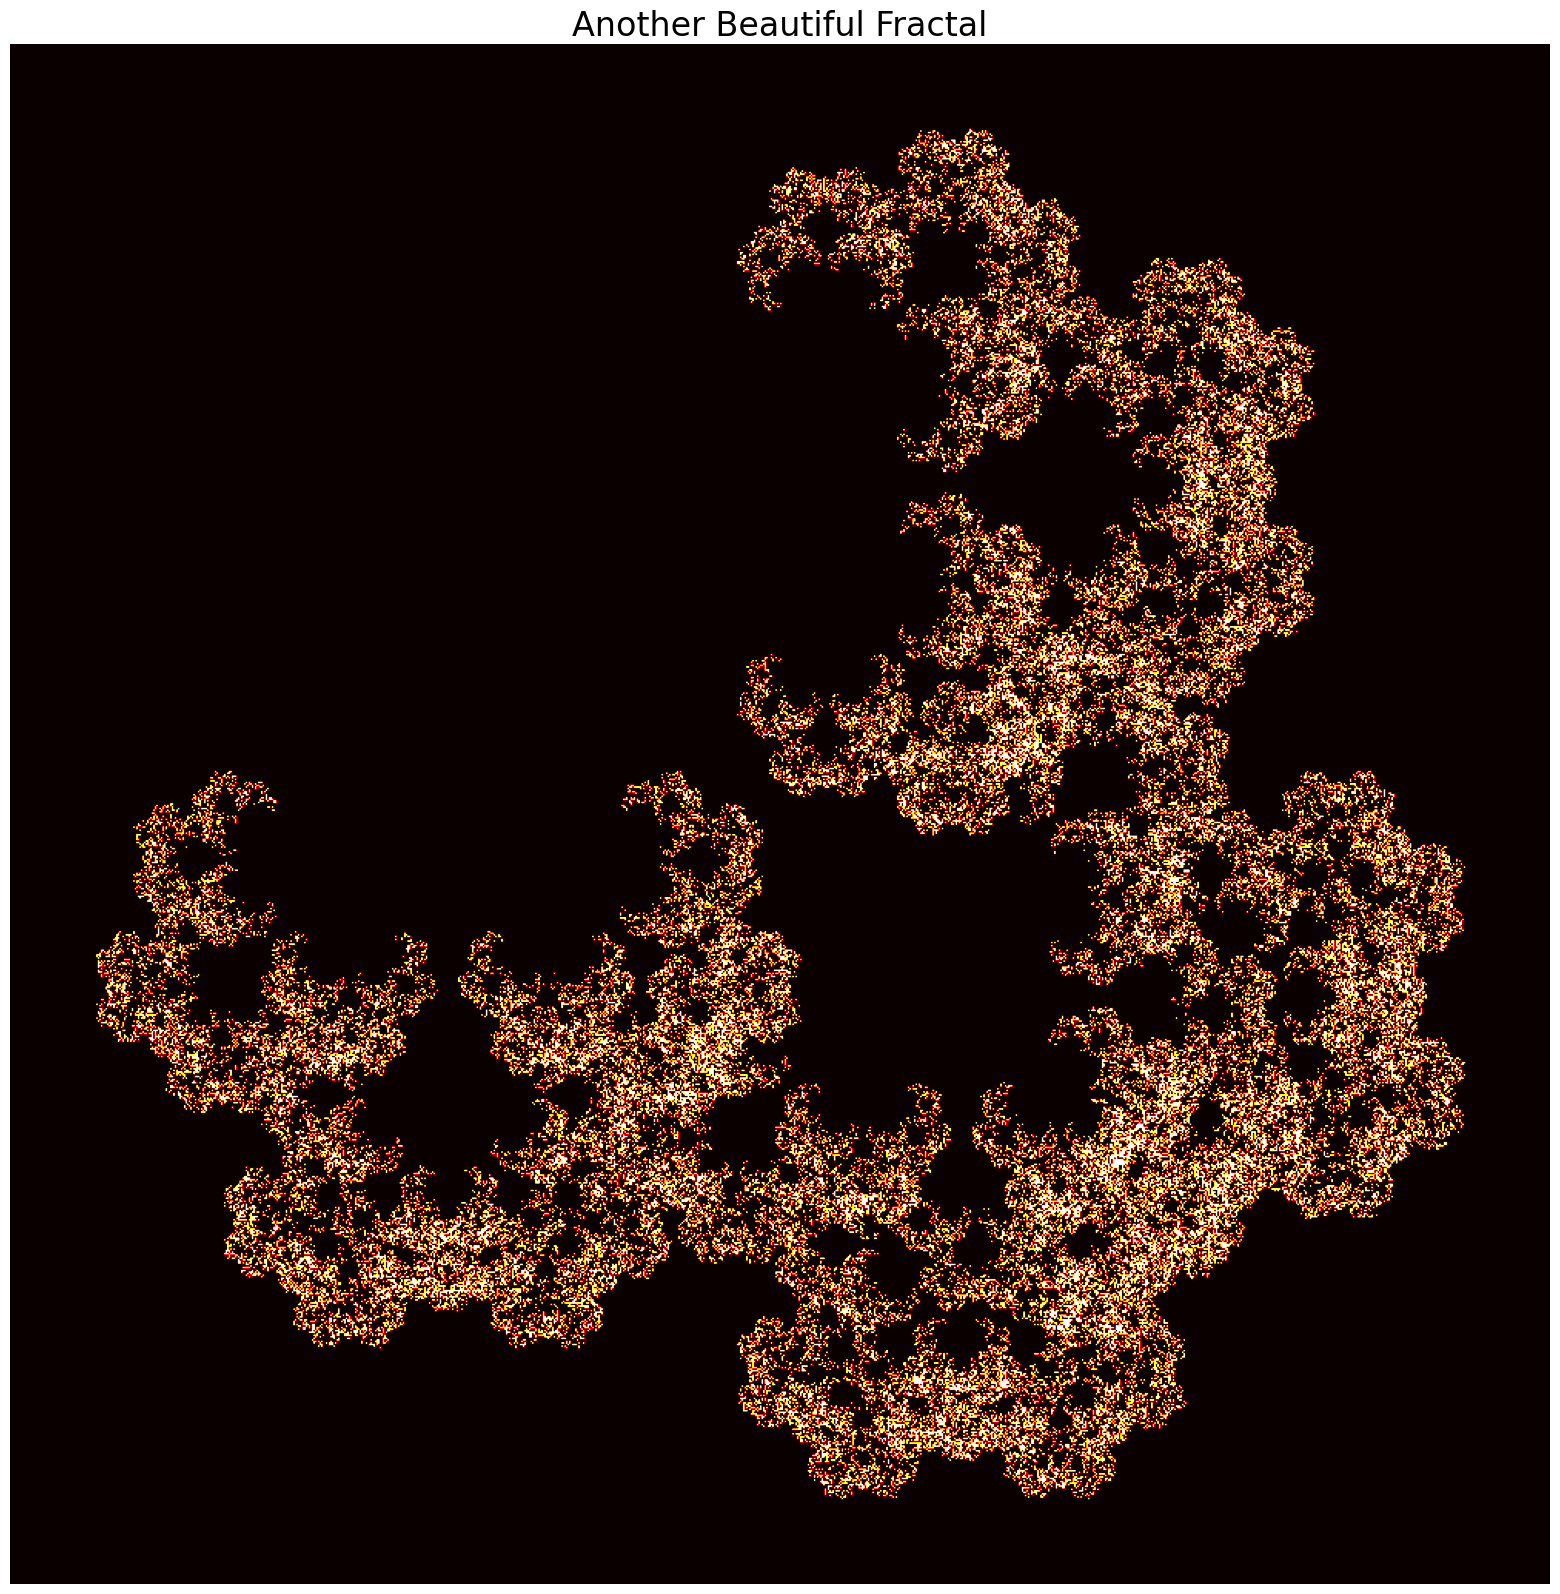

In [14]:
z = 0.5 + 0j
max_iter = 100000
grid_size = 1000
region = [-1.5, 1.5, -1.5, 1.5]


def arm_shrink_rotate(t, A, coef, angle):
    vector = t - A
    rotated_vector = vector * coef * np.exp(1j * angle)
    return A + rotated_vector

funcs = [
    lambda t: arm_shrink_rotate(t, 1 + 0j, coef=0.5, angle=np.pi / 4),
    lambda t: arm_shrink_rotate(t, -1 + 0j, coef=0.5, angle=-np.pi / 4),
    lambda t: arm_shrink_rotate(t, 0 + 1j, coef=0.5, angle=np.pi / 4),
    lambda t: arm_shrink_rotate(t, 0 - 1j, coef=0.5, angle=-np.pi / 4),
]


pixels = np.zeros((grid_size, grid_size), dtype=int)

def scale_to_grid(z, region, grid_size):
    xmin, xmax, ymin, ymax = region
    real_scaled = int((z.real - xmin) / (xmax - xmin) * grid_size)
    imag_scaled = int((z.imag - ymin) / (ymax - ymin) * grid_size)
    return real_scaled, imag_scaled


for n_iter in range(max_iter):
    n_func = np.random.choice(len(funcs))
    z = funcs[n_func](z)

    if n_iter >= 10:
        x, y = scale_to_grid(z, region, grid_size)
        if 0 <= x < grid_size and 0 <= y < grid_size:
            pixels[grid_size - y - 1, x] = 1

plt.figure(figsize=(20, 20))
plt.imshow(pixels, cmap='hot')
plt.title("Another Beautiful Fractal", fontsize=24)
plt.axis('off')
plt.show()


## Часть 6 (бонус). Метод Гаусса или обратные матрицы?

**Задание 6.1 [1.5 балла]** Пусть нам дано матричное уравнение $Ax = B$, где $A$ – матрица размера $n\times n$, а $B$ – матрица размера $n\times m$ (отметим, что это уравнение можно интерпретировать как $m$ систем с векторными правыми частями и однаковыми левыми). Вообще говоря, методов решения таких уравнений очень много, но мы пока рассмотрим два из них, с которыми вы уже хорошо знакомы.
1. Метод Гаусса;
2. Умножение на обратную матрицу: $x = A^{-1}B$.

В этом задании вы попробуете ответить на вопрос о том, какой из этих методов эффективнее. Проведите два эксперимента:
- сравните скорости решения системы при фиксированном `m = 10` и `n`, изменяющемся в пределах от 10 до 1000, например, для `n=10, 50, 100, 200, 500, 1000` (рост числа неизвестных при фиксированном количестве правых частей);
- сравните скорости решения системы при фиксированном `n = 100` и `m`, меняющемся от 10 до 10000, например, для `m = 10, 100, 500, 1000, 2000, 5000, 10000` (рост числа правых частей при фиксированном числе неизвестных).

При проведении экспериментов не возбраняется использовать циклы `for`.

Эксперименты проведите на случайных матрицах, созданных с помощью функции `numpy.random.rand`. Постройте графики времени выполнения функции от размерности (лучше в логарифмическом масштабе). Сделайте выводы (в письменном виде!) о том, какой из методов оказывается лучше в каких обстоятельствах.

Чтобы всё это не казалось вам чёрной магией, найдите число операций (суммарно сложения, умножения и деления), необходимых для решения системы каждым из методов. Обратите внимания на члены суммарной степени 3 (суммарной по $m$ и $n$; члены меньшего порядка можете даже не считать). Постарайтесь объяснить полученные ранее результаты.

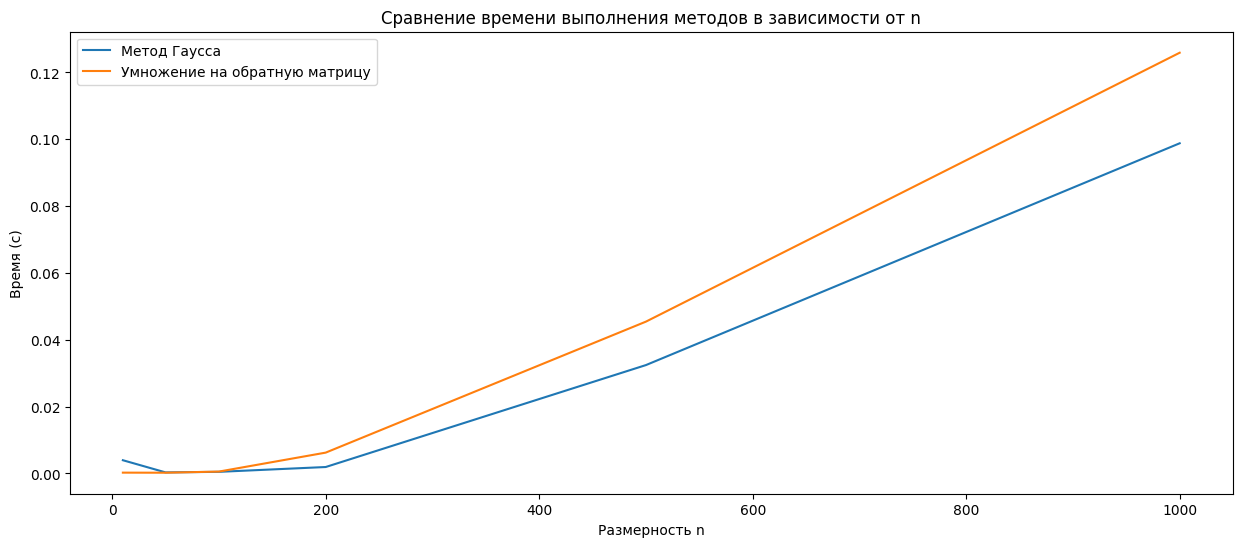

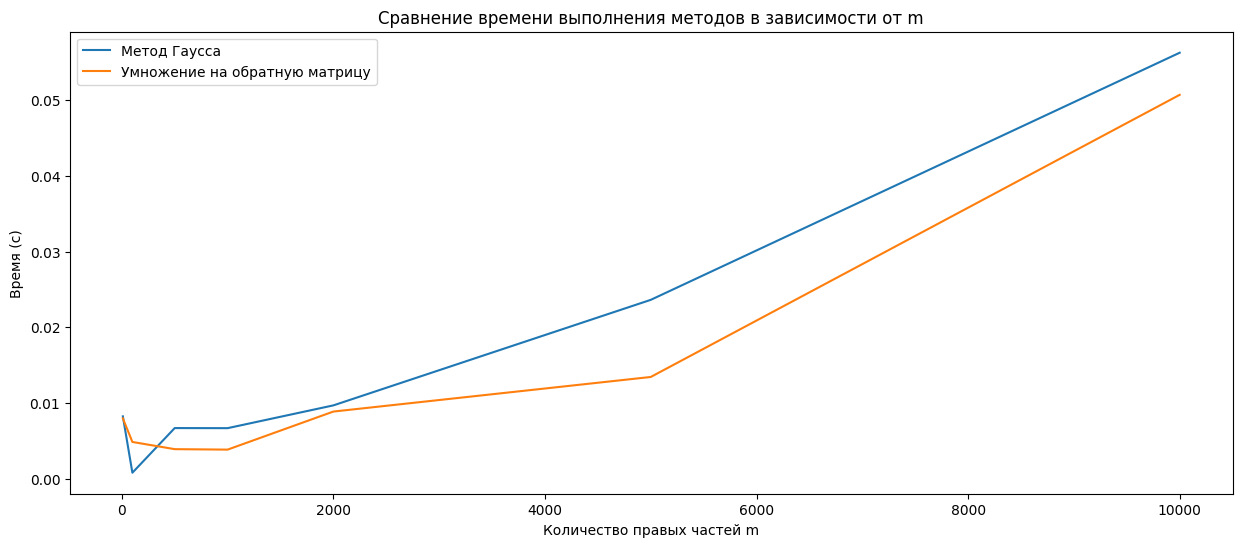

In [106]:
import time
def gauss_method(A, B):
    return sla.solve(A, B)

def inverse_method(A, B):
    A_inv = sla.inv(A)
    return np.dot(A_inv, B)

# Проведение эксперимента для фиксированного m и изменяющегося n
def experiment_1():
    m = 10
    n_values = [10, 50, 100, 200, 500, 1000]

    gauss_times = []
    inverse_times = []

    for n in n_values:
        A = np.random.rand(n, n)
        B = np.random.rand(n, m)

        # Метод Гаусса
        start_time = time.time()
        gauss_method(A, B)
        gauss_times.append(time.time() - start_time)

        # Метод с обратной матрицей
        start_time = time.time()
        inverse_method(A, B)
        inverse_times.append(time.time() - start_time)

    plt.figure(figsize=(15, 6))
    plt.plot(n_values, gauss_times, label="Метод Гаусса")
    plt.plot(n_values, inverse_times, label="Умножение на обратную матрицу")
    plt.xlabel("Размерность n")
    plt.ylabel("Время (с)")
    plt.title("Сравнение времени выполнения методов в зависимости от n")
    plt.legend()
    #plt.grid(True)
    plt.show()

# Проведение эксперимента для фиксированного n и изменяющегося m
def experiment_2():
    n = 100
    m_values = [10, 100, 500, 1000, 2000, 5000, 10000]

    gauss_times = []
    inverse_times = []

    for m in m_values:
        A = np.random.rand(n, n)
        B = np.random.rand(n, m)

        # Метод Гаусса
        start_time = time.time()
        gauss_method(A, B)
        gauss_times.append(time.time() - start_time)

        # Метод с обратной матрицей
        start_time = time.time()
        inverse_method(A, B)
        inverse_times.append(time.time() - start_time)

    plt.figure(figsize=(15, 6))
    plt.plot(m_values, gauss_times, label="Метод Гаусса")
    plt.plot(m_values, inverse_times, label="Умножение на обратную матрицу")
    plt.xlabel("Количество правых частей m")
    plt.ylabel("Время (с)")
    plt.title("Сравнение времени выполнения методов в зависимости от m")
    plt.legend()
    #plt.grid(True)
    plt.show()

experiment_1()
experiment_2()



Невооруженным взглядом видно, что при фиксированном $m$ метод Гаусса выполняется быстрее, а при фиксированном $n$ - метод с обратной матрицей более эффективен.
Рассмотрим число операций, необходимых для решения системы методом Гаусса: \\
1. Этап приведения к ступенчатому виду: \\
  На каждом шаге для $i$-й строки нам нужно обработать оставшиеся $n-i$ строк. Каждая строка имеет длину $n$. Тогла сложность на этом этапе: \\
  $$\sum_{i = 1}^n(n-i)n = O\big((n-1)n + (n-2)n + ...+n\big) = O\Big(\frac{n-1+1}{2} \cdot n \cdot n\Big)  = O(n^3)$$
2.Этап нахождения решения для одной правой части: \\
  Для каждой строки матрицы(всего $n$ строк) мы решаем одну переменную. Так как для каждой переменной требуется решить уравнение с $n$ переменными,  то сложность на этом этапе: $O(n^2)$
3. Нахождение решений для $m$ правых частей: \\
   Очевидно, будет $O(n^2m)$ \\

Итоговая сложность: $O(n^3+n^2m)$

Рассмотим число операций, необходимых для решения системы методом с обратной матрицей: \\
1. Этап нахождения обратной матрицы $A^{-1}$ требует $O(n^3)$
2. Этап умножения $A^{-1}$ (размера $n \times n$) на $B$ (размера $n \times m$) требует $O(n^2m)$
3. Итоговая сложность: $O(n^3+ n^2m)$

Теперь поймем, почему хоть у обоих методов одинаковая ассимптотическая сложность, но выполняются они за разное время: \\
1) Когда $m$ фиксировано, мы обычно берем небольшое $m$.

В методе Гаусса:

Преобразование $A$ делается один раз ($O(n^3)$). Так как столбцов $B$ немного, то система решается суммарно для всех столбцов за незначительное время, при этом используются  только операции сложения.

В методе с обратной матрицей:

Обратная матрица $A^{-1}$ считается один раз($O(n^3)$). Затем происходит умножение $A^{-1} \cdot B$, а это требует операций сложения и умножения.

Поэтому при фиксированном $m$ метод Гаусса более эффективен.


2) Когда $n$ фиксировано, но $m$ становится большим, нужно решать систему для большого количества столбцов $B$.

В методе Гаусса:

Преобразование $A$ делается один раз ($O(n^3)$).Но затем для каждого столбца $B$ система решается отдельно ($O(n^2)$).
Если столбцов много, время растёт пропорционально $m$.

В методе с обратной матрицей:

Обратная матрица $A^{-1}$ считается один раз($O(n^3)$).
Затем все столбцы $B$ обрабатываются одновременно через умножение
$A^{-1} \cdot B$.
Большое число столбцов обрабатывается "оптом", что делает метод с обратной матрицей боллее эффективным, чем метод Гаусса.

Общий вывод:

Метод Гаусса более эффективен при фиксированном $m$ \\
Метод с обратной матрицей более эффективен при фиксированном $n$
